# Tarefa 4 — Sequenciamento do socorro por Têmpera Simulada

Um socorrista está na base. Há uma vítima amarela a duas células e uma vermelha do outro lado do mapa. **Quanto a parada na amarela atrasaria o atendimento da vermelha?** A resposta depende da posição das duas. Uma amarela quase no caminho pode antecipar um atendimento com um pequeno acréscimo de percurso. Outra, à mesma distância da base, pode exigir um desvio considerável. Uma lista ordenada apenas pela cor da triagem daria a mesma resposta nos dois casos.

Na [Tarefa 3](03%20-%20Clustering.ipynb), o K-Means identificou sete agrupamentos considerando a posição e a probabilidade estimada de sobrevivência. Nesta etapa distinguimos duas decisões. A **atribuição** define quem responde por cada vítima. O **sequenciamento** determina em que ordem o agente visita as vítimas sob sua responsabilidade. Depois da atribuição, as cinco rotas podem ser executadas em paralelo, cada uma com partida e retorno à base.

O problema é de **otimização combinatória**. Para uma atribuição com $n$ vítimas distintas, há $n!$ ordens possíveis antes de considerar as restrições de fase. Definimos o que torna uma ordem preferível a outra e usamos a Têmpera Simulada para procurar permutações de baixo custo. O [enunciado](docs/enunciados/T04_Sequenciamento.pdf) especifica o cenário, a elegibilidade dos agentes e a distância que devemos medir.

## 1. O que cada etapa fornece ao planejador

O mapa contém os sinais das vítimas e suas coordenadas. A Tarefa 1 fornece a MLP que estima a triagem (`tri`). A Tarefa 2 fornece a MLP e o escalonador que estimam a probabilidade de sobrevivência (`sobr`). Como o mapa traz `-1` nesses dois campos, aplicamos os modelos já ajustados aos mesmos atributos da Tarefa 3. O vínculo entre vítima e cluster vem diretamente dos arquivos `cluster_*.txt`. Assim, comparar duas rotas mantém fixos os agrupamentos e as predições.

A base ocupa a célula absoluta $(30,40)$. As colunas `x_rel` e `y_rel` já descontam essa posição, portanto a base para todos os cálculos de distância é $(0,0)$. O ID 0 identifica uma vítima válida. A matriz de distâncias reserva uma posição própria para a base.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display

from src.clustering import CORES_TRI, ESPACIAIS
from src import sequenciamento as seq

raiz = Path.cwd()
vitimas = seq.carregar_cenario(raiz)
geo = seq.Geometria.do_quadro(vitimas)
classes = {0: "VD", 1: "AM", 2: "VM", 3: "PR"}
perfil = pd.crosstab(vitimas.cluster, vitimas.tri).reindex(columns=classes, fill_value=0)
perfil = perfil.rename(columns=classes)
perfil["Até 12 anos"] = vitimas.idade.le(12).groupby(vitimas.cluster).sum()
perfil["μ sobr"] = vitimas.sobr.groupby(vitimas.cluster).mean()
display(perfil.round(3))

tri,VD,AM,VM,PR,Até 12 anos,μ sobr
cluster,,,,,,
1,20,26,1,0,19,0.842
2,36,31,2,0,21,0.855
3,0,0,33,19,11,0.401
4,0,0,20,22,6,0.334
5,0,0,24,46,7,0.313
6,39,30,10,0,28,0.837
7,6,18,19,8,14,0.627


A triagem tem duas funções no planejamento. As vítimas vermelhas e amarelas formam a fase de ida e as verdes são atendidas no retorno. A política adotada para esta simulação exclui as classificadas como pretas do socorro ativo. No cenário, essa escolha separa **315 vítimas nas rotas** e **95 registradas como excluídas**. A tabela permite localizar as exclusões no cluster de origem. A coluna PR da tabela final conta somente quem participa do percurso.

A estimativa `sobr` participou do agrupamento e caracteriza a composição das rotas. Usá-la novamente como urgência exigiria saber quanto a espera altera a sobrevivência de cada vítima. O regressor das etapas anteriores estima a probabilidade a partir dos sinais disponíveis e não fornece essa relação temporal.

## 2. Quem fica responsável por cada vítima?

Cada cluster misto pode fornecer um bloco de vítimas ativas de **até 12 anos** e outro de vítimas **acima de 12 anos**. O centroide de cada bloco é a média das coordenadas originais de seus integrantes. Isso importa porque duas faixas etárias de um mesmo cluster podem ocupar partes diferentes do mapa. A responsabilidade é atribuída ao bloco inteiro, preservando o cluster de origem de cada ID.

Os centroides da Tarefa 3 sugerem três concentrações geográficas principais para a distribuição inicial dos maiores de 12 anos. C1 e C4 aparecem a noroeste, C2 e C3 a sudoeste, e C5, C6 e C7 a leste. Usamos essa geometria para definir duas divisões sobrepostas do mapa quadrado.

| Agentes | Divisão inicial | Blocos atribuídos |
| --- | --- | --- |
| 1 e 2 | Metade oeste e metade leste | Vítimas ativas com idade ≤ 12 |
| 3, 4 e 5 | Parte superior e inferior dos dois terços a oeste, e terço leste inteiro | Vítimas ativas com idade > 12 |

A largura do mapa é de 75 células. Na camada pediátrica, a fronteira passa pelo centro da coluna absoluta 37. Na outra camada, o terço leste começa na borda entre as colunas 49 e 50. Dividimos a área restante na altura da linha absoluta 37. Essas divisões correspondem a metades e terços da **área de referência**. O número de vítimas e a distância necessária para atendê-las dependem da sua distribuição. No mapa abaixo, a estrela marca a base e os círculos com rótulos indicam os centroides dos blocos.

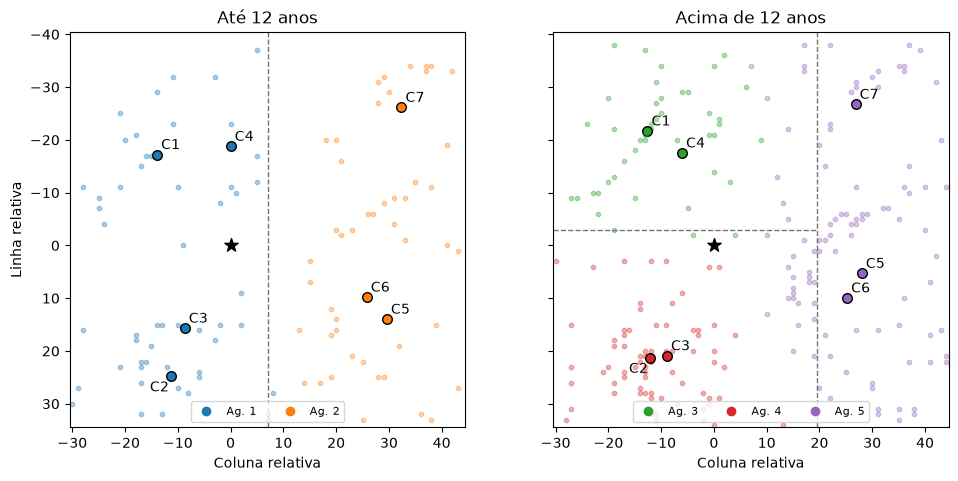

In [2]:
atribuicao, blocos, cargas = seq.atribuir(vitimas, geo)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.7), sharex=True, sharey=True, layout="constrained")
for ax, pediatrico, titulo in zip(eixos, [True, False], ["Até 12 anos", "Acima de 12 anos"]):
    for b in blocos.loc[blocos.pediatrico == pediatrico].itertuples():
        membros = vitimas.loc[(vitimas.cluster == b.cluster) & (vitimas.tri != seq.PRETA)
                              & ((vitimas.idade <= 12) == pediatrico)]
        cor = f"C{b.inicial - 1}"
        ax.scatter(membros.x_rel, membros.y_rel, s=10, color=cor, alpha=0.35)
        ax.scatter(b.x, b.y, s=48, color=cor, edgecolors="black")
        deslocamento = (-15, -11) if b.cluster == 2 else (3, 4)
        ax.annotate(f"C{b.cluster}", (b.x, b.y), xytext=deslocamento, textcoords="offset points")
    ax.axvline(7 if pediatrico else 19.5, ls="--", color="0.45", lw=1)
    if not pediatrico:
        ax.hlines(-3, -30.5, 19.5, ls="--", color="0.45", lw=1)
    ax.scatter(0, 0, marker="*", s=100, color="black")
    ax.set(title=titulo, xlabel="Coluna relativa", xlim=(-30.5, 44.5), ylim=(34.5, -40.5),
           aspect="equal")
    agentes = [1, 2] if pediatrico else [3, 4, 5]
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=f"C{a-1}", label=f"Ag. {a}")
                       for a in agentes], ncols=len(agentes), loc="lower center", fontsize=8)
eixos[0].set_ylabel("Linha relativa")
plt.show()

### Cooperação quando um agente concentra trabalho

Uma área pequena pode exigir uma rota longa. Para estimar a carga de cada agente $a$, partimos da base, visitamos sucessivamente a vítima mais próxima ainda pendente e voltamos à base. Essa heurística do **vizinho mais próximo** fornece uma distância estimada $D_a^{NN}$. Em caso de empate, escolhemos o menor ID. Também contamos as $N_a$ vítimas da rota.

$$W_a=\frac{D_a^{NN}}{\overline D_{\mathrm{inicial}}}
      +\frac{N_a}{\overline N_{\mathrm{inicial}}}, \qquad M=\max_a W_a.$$

Os denominadores são as médias iniciais entre os cinco agentes, com piso de 1. Os dois termos têm o mesmo peso. A distância representa o deslocamento, e a contagem representa o trabalho associado aos atendimentos. Como faltam tempos de atendimento e velocidades, $W_a$ é uma medida adimensional de carga.

Depois de reservar todas as crianças a 1 e 2, simulamos transferências de blocos de maiores de 12 anos para o agente pediátrico da respectiva metade. Recalculamos as duas rotas afetadas e aceitamos a alternativa que mais reduz $M$, desde que a distância total estimada permaneça até 5% acima da inicial. Um empate é resolvido pela menor distância total. O processo termina quando nenhum bloco melhora o critério. O limite de 5% é uma escolha de modelagem que restringe o custo da cooperação.

In [3]:
comparacao_cargas = cargas.reset_index().pivot(index="agente", columns="atribuição",
                                                values=["vítimas", "distância NN", "carga"])
display(comparacao_cargas.reindex(columns=["inicial", "final"], level="atribuição").round(2))
display(blocos.loc[blocos.inicial != blocos.agente, ["cluster", "n", "inicial", "agente"]]
        .rename(columns={"n": "vítimas transferidas", "inicial": "origem", "agente": "destino"}))

vítimas       distância NN           carga      
atribuição inicial final      inicial   final inicial final
agente                                                     
1             54.0  54.0       417.70  417.70    2.09  2.09
2             47.0  76.0       295.96  377.39    1.62  2.32
3             44.0  44.0       224.90  224.90    1.36  1.36
4             71.0  71.0       299.34  299.34    2.01  2.01
5             99.0  70.0       459.72  296.87    2.93  1.99

,cluster,vítimas transferidas,origem,destino
12,7,29,5,2


Nesse cenário, o agente 5 cede ao agente 2 o bloco de 29 vítimas acima de 12 anos do cluster 7. O agente 2 já responde pelas crianças desse cluster. A carga máxima da equipe cai de aproximadamente 2,93 para 2,32 na estimativa inicial de percurso. Isso demonstra um efeito da **atribuição**, antes de qualquer otimização das sequências. A prioridade pediátrica define quem responde pelas crianças. Uma vez definida a rota do agente 2, um adulto vermelho pode receber atendimento antes de uma criança verde.

## 3. Como transformar uma política de socorro em uma função de custo?

Seja $\pi=(v_1,\ldots,v_n)$ a ordem de visita de um agente e sejam $v_0=v_{n+1}=B$ a base. Cada trecho tem comprimento euclidiano $d(u,v)=\sqrt{(x_u-x_v)^2+(y_u-y_v)^2}$. O modelo usa segmentos de reta e desconsidera os obstáculos, conforme a métrica do enunciado. Medimos três propriedades da mesma sequência.

**Distância total $D$.** Somamos todos os trechos, inclusive o último regresso à base. Duas rotas percorridas em sentidos opostos podem ter o mesmo comprimento e produzir ordens de atendimento muito diferentes.

$$D(\pi)=\sum_{i=1}^{n+1}d(v_{i-1},v_i).$$

**Latência ponderada $L$.** Ao chegar à vítima $v_i$, o agente já percorreu $A_i$ células de distância acumulada. Uma parada antecipada beneficia aquela vítima e pode atrasar as seguintes. Os pesos $w_{\mathrm{VM}}=3$, $w_{\mathrm{AM}}=2$ e $w_{\mathrm{VD}}=1$ expressam o custo relativo de um mesmo acréscimo de espera na política proposta. A latência está em unidades de distância percorrida até o atendimento.

$$A_i=\sum_{j=1}^{i} d(v_{j-1},v_j), \qquad
L(\pi)=\frac{\sum_{i=1}^n w_i A_i}{\sum_{i=1}^n w_i}.$$

**Inversão radial $R$.** O raio $r_i=d(B,v_i)$ mede o afastamento em relação à base. Na ida, uma passagem de raio 5 para raio 3 acrescenta 2 à penalidade. No retorno, a mesma passagem contribui zero. Para cada trecho, definimos $\Delta r=r_{\mathrm{destino}}-r_{\mathrm{origem}}$.

$$R(\pi)=\sum_{\mathrm{ida}}\max(0,-\Delta r)
       +\sum_{\mathrm{retorno}}\max(0,\Delta r).$$

O trecho entre a última urgente e a primeira verde já pertence ao retorno. Se houver apenas verdes, o primeiro deslocamento da base até uma verde conta em $D$ e em sua latência, e as inversões de retorno passam a ser medidas a partir dessa vítima. Sem verdes, o último trecho volta diretamente à base.

**Combinação.** Fixamos para cada agente uma referência $D_0=\max(D_{\mathrm{vizinho\ mais\ próximo}},1)$ calculada com a ordem livre. A busca minimiza

$$J(\pi)=\frac{D(\pi)+\lambda_p L(\pi)+\lambda_r R(\pi)}{D_0}.$$

Há duas naturezas de decisão. A elegibilidade por idade e a separação entre urgentes na ida e verdes no retorno são **restrições** da estratégia completa. A preferência pelas vermelhas e o afastamento progressivo são **penalidades graduais**. Em particular, aumentar $\lambda_r$ torna mais caro inverter a direção radial e ainda permite um pequeno recuo quando a economia nos outros termos o justifica.

### Exemplo calculado com três vítimas

Colocamos uma amarela em $(1,1)$, uma vermelha em $(6,0)$ e uma verde em $(1,0)$. Compare as duas ordens admissíveis. Em ambas, a verde fica para o retorno. A célula usa a mesma implementação da função de custo aplicada ao mapa.

In [4]:
exemplo = pd.DataFrame({"x_rel": [1, 6, 1], "y_rel": [1, 0, 0],
                        "tri": [seq.AMARELA, seq.VERMELHA, seq.VERDE]})
g = seq.Geometria.do_quadro(exemplo)
d0 = g.trechos(g.vizinho_proximo(exemplo.index)).sum()
comparacao = []
for nome, ordem in [("VM → AM → VD", [1, 0, 2]), ("AM → VM → VD", [0, 1, 2])]:
    rota = np.array(ordem)
    d, latencia, radial = seq.componentes(g, rota, corte=2)
    chegada = pd.Series(g.trechos(rota)[:-1].cumsum(), index=rota)
    comparacao.append({"ordem": nome, "chegada VM": chegada[1], "chegada AM": chegada[0],
                       "D": d, "L": latencia, "R": radial, "J": (d + 0.5*latencia + 0.5*radial)/d0})
display(pd.DataFrame(comparacao).set_index("ordem").round(3))

,chegada VM,chegada AM,D,L,R,J
ordem,,,,,,
VM → AM → VD,6.000,11.099,13.099,8.716,4.586,1.508
AM → VM → VD,6.513,1.414,12.513,5.647,0.000,1.171


Atender a amarela primeiro muda a chegada à vermelha de $6$ para $\sqrt{2}+\sqrt{26}\approx6{,}51$. Em contrapartida, a amarela recebe atendimento após cerca de $1{,}41$ unidade de deslocamento, em vez de $11{,}10$. Mesmo com peso maior para a vermelha, esse desvio antecipado reduz a latência ponderada. A posição da amarela explica a decisão. O algoritmo pode inverter a preferência em outra geometria.

## 4. Como a Têmpera Simulada procura uma ordem melhor?

O vizinho mais próximo escolhe o próximo passo sem considerar o restante da rota. A **busca local** parte dessa solução e compara permutações vizinhas. Na estratégia completa, representamos a rota como a concatenação de duas listas, $[\mathrm{VM,AM}\ldots]\;|\;[\mathrm{VD}\ldots]$. Cada vizinho altera somente uma das fases. Avaliamos o percurso inteiro após a mudança, pois a última urgente e a primeira verde definem juntas o custo da transição.

| Movimento | Operação sobre as posições de uma fase | Exemplo |
| --- | --- | --- |
| Troca | Permutar dois IDs | $[a,b,c,d]\to[c,b,a,d]$ |
| Inserção | Remover um ID e recolocá-lo em outra posição | $[a,b,c,d]\to[b,c,a,d]$ |
| Inversão | Percorrer um segmento em sentido inverso | $[a,b,c,d]\to[a,d,c,b]$ |

Sorteamos uniformemente uma fase com pelo menos dois elementos e, nela, um dos três movimentos com igual probabilidade. A construção preserva os IDs, o agente responsável e a composição de cada fase. Caso a rota não admita movimento, mantemos a ordem inicial.

Se $\Delta=J(\pi')-J(\pi)\leq 0$, aceitamos a candidata. Para $\Delta>0$, aceitamos com probabilidade $\exp(-\Delta/T)$. Isso permite atravessar um mínimo local. Por exemplo, uma piora de 0,02 tem cerca de 82% de chance de aceitação com $T=0{,}10$ e apenas 14% com $T=0{,}01$. A temperatura controla a exploração. Guardamos a **melhor solução visitada**, inclusive durante a calibração inicial.

Amostramos até 48 vizinhos da rota inicial para estimar a piora positiva mediana $m$. Usamos $T_0=-m/\ln(0{,}8)$, ou $0{,}01$ se a amostra não contiver pioras. A cada $\max(20,n)$ propostas reduzimos a temperatura geometricamente até $0{,}001\,T_0$ no último nível. Ajustamos a razão geométrica ao orçamento disponível para que todas as variantes percorram a mesma faixa relativa de temperaturas. A calibração entra no orçamento.

## 5. Que comparação permite atribuir um efeito a cada escolha?

Fixamos a atribuição dos cinco agentes e alteramos um elemento da política por vez. **NN** designa a referência do vizinho mais próximo com ordem livre. **NN-fases** é a referência que visita primeiro as urgentes e depois as verdes. Se uma rota contiver somente verdes, essa segunda referência começa pela mais distante da base.

| Método | Ordem permitida | Critério minimizado pela busca | Comparação principal |
| --- | --- | --- | --- |
| NN e NN-fases | Livre ou em duas fases | Escolha gulosa do próximo passo | Pontos de partida |
| A | Livre | Distância | A × NN mede o efeito da busca sobre a distância |
| B | Livre | Distância e latência | B × A investiga o efeito da prioridade |
| C | Urgentes na ida, verdes no retorno | Distância e latência | C × B investiga o custo de impor as fases |
| D | As mesmas duas fases | Distância, latência e inversão radial | D × C isola a introdução do termo radial |

Usamos os coeficientes iniciais `0,5` para prioridade e progressão radial e repetimos cada variante com cinco sementes. As sementes e o orçamento controlam a comparação entre buscas estocásticas. A célula seguinte executa o experimento completo. A comparação de sensibilidade pode ser repetida alterando um coeficiente para `0,25` ou `1` e mantendo o outro fixo. Esses pesos expressam uma preferência operacional e podem ser discutidos a partir das métricas observadas.

In [5]:
sementes = [11, 23, 37, 53, 71]
orcamento = 50_000  # propostas por agente, variante e semente
lambda_p, lambda_r = 0.5, 0.5
experimentos, rotas, semente_final = seq.experimentar(
    vitimas, geo, atribuicao, sementes, orcamento, lambda_p, lambda_r
)
tabela, rastro = seq.tabelas_plano(vitimas, geo, atribuicao, rotas)

O custo $J$ serve para comparar permutações **sob a mesma função objetivo**. Para comparar as variantes, examinamos medidas em unidades comuns. Somamos as distâncias dos cinco agentes em cada execução. Para a latência por classe, cada vítima tem o mesmo peso dentro da classe, mesmo quando os agentes atendem quantidades diferentes. Calculamos ainda uma medida radial comparável em qualquer rota, dividindo-a na primeira visita de raio máximo (`R_ápice`). Já `R_fases`, usada em D, divide a rota na transição de urgentes para verdes.

A tabela resume as execuções por média e desvio-padrão populacional entre sementes. As duas referências são determinísticas. Observe quanto custa antecipar as vermelhas e se a redução de inversões em D aparece também na curva de raio. A busca guarda o menor $J$ visitado em cada execução, o que permite que uma métrica isolada piore enquanto o compromisso global melhora.

In [6]:
por_execucao = []
for (metodo, semente), grupo in experimentos.groupby(["metodo", "semente"], dropna=False):
    linha = {"método": metodo, "semente": semente, "D total": grupo.D.sum(),
             "R ápice": grupo["R_ápice"].sum(), "R fases": grupo.R_fases.sum(min_count=1)}
    for cor in ["VM", "AM", "VD"]:
        pesos = grupo.agente.map(tabela.set_index("Agente")[cor])
        linha[f"L {cor}"] = ((grupo[f"L_{cor}"] * pesos).sum() / pesos.sum()
                              if pesos.sum() else np.nan)
    por_execucao.append(linha)
frota = pd.DataFrame(por_execucao)
por_metodo = frota.drop(columns="semente").groupby("método")
ordem_metodos = ["NN", "A", "B", "NN-fases", "C", "D"]
display(por_metodo.mean().reindex(ordem_metodos).round(2))
display(por_metodo.std(ddof=0).reindex(ordem_metodos).round(2).rename_axis("método (σ)"))

,D total,R ápice,R fases,L VM,L AM,L VD
método,,,,,,
NN,1616.21,271.16,NaN,131.03,138.94,127.87
A,1415.38,244.07,NaN,148.06,143.15,145.75
B,1413.39,226.07,NaN,123.20,137.11,135.44
NN-fases,2126.65,434.90,507.55,119.79,126.16,323.40
C,1879.76,382.75,440.12,108.97,120.61,292.07
D,1892.14,333.87,387.26,114.73,125.07,296.08


,D total,R ápice,R fases,L VM,L AM,L VD
método (σ),,,,,,
NN,0.00,0.00,NaN,0.00,0.00,0.00
A,18.08,15.86,NaN,5.17,7.83,4.28
B,17.23,5.75,NaN,3.01,8.48,7.57
NN-fases,0.00,0.00,0.00,0.00,0.00,0.00
C,19.25,6.18,13.12,5.97,2.17,4.36
D,14.52,10.26,23.56,2.50,6.23,4.48


**Leitura da comparação.** Em B × A, as vermelhas são atendidas 24,86
células de deslocamento mais cedo em média, com distância total semelhante.
Em C × B, a obrigação de deixar verdes para o retorno antecipa vermelhas
e amarelas, ao custo de 466,37 células a mais no percurso e 156,63 células
a mais até o atendimento médio das verdes. Em D × C, a soma das inversões
no corte de fase cai de 440,12 para 387,26 células, enquanto o trajeto
aumenta 12,38 células e a chegada média piora nas três classes.

Em relação a NN-fases, D reduz a distância total média em 234,51 células
(11,0%) e antecipa em média as três classes. Na semente selecionada (71),
as amarelas chegam a 127,90 células de deslocamento acumulado, acima
das 126,16 da referência bifásica.

## 6. O que a sequência escolhida permite observar?

Dentro da variante D com os pesos desta execução, escolhemos a semente com a menor soma dos cinco valores de $J$. Assim, todas as rotas apresentadas pertencem a uma mesma execução. Cada linha da primeira tabela corresponde a uma rota que parte da base e volta a ela. A média e o desvio-padrão populacional de `sobr` descrevem quem foi atribuído ao agente. Uma permutação do mesmo conjunto de vítimas preserva ambas as estatísticas.

In [7]:
print(f"Semente da frota selecionada: {semente_final}")
display(tabela.round(3))
display(pd.DataFrame({"μ entre sequências": tabela[["Total", "Distância"]].mean(),
                      "σ entre sequências": tabela[["Total", "Distância"]].std(ddof=0)}).round(3))
display(pd.crosstab(rastro.cluster, rastro["situação"], margins=True, margins_name="Total"))

Semente da frota selecionada: 71


,Seq.,Agente,VD,AM,VM,PR,Total,Distância,μ sobr,σ sobr
0,1,1,19,20,15,0,54,450.320,0.761,0.187
1,2,2,19,30,27,0,76,469.766,0.741,0.169
2,3,3,13,15,16,0,44,244.208,0.697,0.207
3,4,4,24,22,25,0,71,344.060,0.737,0.181
4,5,5,26,18,26,0,70,364.655,0.722,0.201


,μ entre sequências,σ entre sequências
Total,63.000,12.033
Distância,374.602,81.023


situação,excluída por triagem preta,ida,retorno,Total
cluster,,,,
1,0,27,20,47
2,0,33,36,69
3,19,33,0,52
4,22,20,0,42
5,46,24,0,70
6,0,40,39,79
7,8,37,6,51
Total,95,214,101,410


Cada linha da figura apresenta um agente. No mapa, a linha contínua percorre as urgentes e a tracejada passa pelas verdes até a base. A curva ao lado registra o raio a cada visita. Uma queda na ida ou uma subida no retorno correspondem a inversões radiais. A distância ao longo do mapa e o perfil de raio se complementam, pois um deslocamento lateral longo pode ocorrer sem alteração do raio. A numeração do eixo horizontal inclui a partida na posição zero e a chegada à base na última posição.

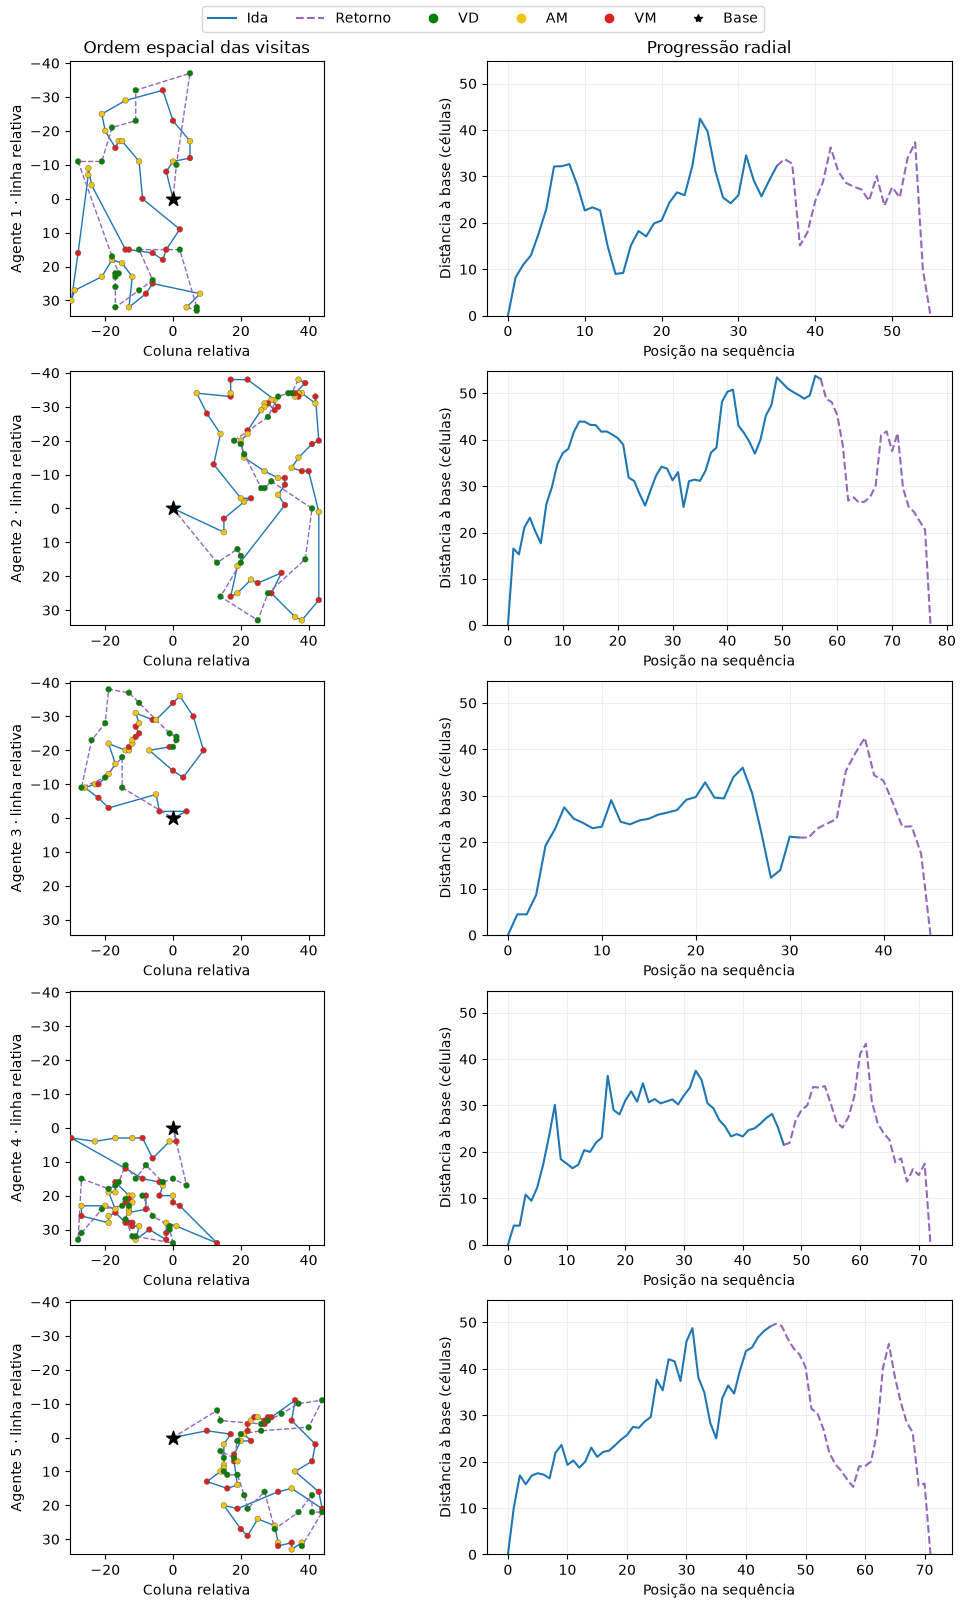

In [8]:
fig, eixos = plt.subplots(5, 2, figsize=(10, 16), layout="constrained")
for (mapa_ax, raio_ax), (agente, rota) in zip(eixos, sorted(rotas.items())):
    grupo = vitimas.loc[rota]
    xy = np.vstack([[0, 0], grupo[ESPACIAIS].to_numpy(), [0, 0]])
    raio = np.linalg.norm(xy, axis=1)
    corte = int(grupo.tri.ne(seq.VERDE).sum())
    virada = corte if corte else min(1, len(rota))
    for trecho, cor, estilo in [(slice(None, virada+1), "C0", "-"),
                                (slice(virada, None), "C4", "--")]:
        mapa_ax.plot(*xy[trecho].T, color=cor, ls=estilo, lw=1)
        raio_ax.plot(np.arange(len(xy))[trecho], raio[trecho], color=cor, ls=estilo)
    mapa_ax.scatter(grupo.x_rel, grupo.y_rel, color=np.array(CORES_TRI)[grupo.tri], s=17,
                    edgecolors="0.35", linewidths=0.3, zorder=3)
    mapa_ax.scatter(0, 0, marker="*", s=110, color="black", zorder=4)
    mapa_ax.set(aspect="equal", xlim=(-30.5, 44.5), ylim=(34.5, -40.5),
                ylabel=f"Agente {agente} · linha relativa", xlabel="Coluna relativa")
    raio_ax.set(xlabel="Posição na sequência", ylabel="Distância à base (células)",
                ylim=(0, geo.d[geo.base].max() + 1))
    raio_ax.grid(alpha=0.2)
eixos[0, 0].set_title("Ordem espacial das visitas")
eixos[0, 1].set_title("Progressão radial")
legenda = [Line2D([], [], color="C0", label="Ida"), Line2D([], [], ls="--", color="C4", label="Retorno")]
legenda += [Line2D([], [], ls="", marker="o", color=CORES_TRI[i], label=classes[i]) for i in range(3)]
legenda += [Line2D([], [], ls="", marker="*", color="black", label="Base")]
fig.legend(handles=legenda, loc="outside upper center", ncols=6)
plt.show()

Os perfis ainda contêm quedas na ida e subidas no retorno. A penalidade
radial reduz essas variações em média, permitindo que a busca aceite
inversões quando elas compensam nos demais termos do custo.

### Leitura dos arquivos de saída

Na pasta de cada socorrista, `rota.txt` contém a sequência operacional completa e cada `cluster_j.txt` contém os IDs do agrupamento original $j$ atendidos por esse socorrista, na ordem em que aparecem na rota. Um agente pode intercalar clusters, e um cluster misto pode aparecer nas pastas de dois ou mais agentes. A coluna `ordem` de `atribuicao.csv` permite recompor essa intercalação. Cada ID do cenário tem um único registro, inclusive as exclusões pela política de triagem.

O enunciado pede arquivos ordenados por cluster e inclui a classe preta no exemplo da tabela. A convenção aqui permite verificar exatamente quais IDs cada agente planeja atender. Para a entrega, cabe confirmar com o professor a divisão de um cluster entre pastas de agentes e o registro separado das vítimas pretas.

Antes da exportação, conferimos cobertura, unicidade, elegibilidade etária e composição das fases. `sequencias.csv` registra a tabela da frota selecionada e `experimentos.csv` conserva as métricas das demais execuções. A última célula grava os resultados da configuração executada.

In [9]:
saida = raiz / "resultados/sequenciamento"
seq.exportar(saida, tabela, rastro, experimentos)